In [63]:
from pathlib import Path
import pandas as pd

import soundfile as sf

import matplotlib.pyplot as plt


In [2]:
root_dir = Path("/home/jet/UCDavis/Gesture_Speech_Semantic_Grounding/Semantic Grounding Project/annotated_using_kipp_annotations_active_learning")

In [3]:
video_extensions = {".mp4"}

In [4]:
data = []
video_suffix_set = set()

for video_path in root_dir.rglob("*"):
    if video_path.suffix.lower() in video_extensions:
        # Assuming your structure is root_dir / category_folder / video.mp4
        # The parent folder name acts as the category/label
        category = video_path.parent.name
        filename = video_path.name
        relative_path = str(video_path.relative_to(root_dir))
        absolute_path = str(video_path.resolve())
    
        data.append({
            "filename": filename,
            "category": category,
            "relative_path": relative_path,
            "absolute_path": absolute_path,
            "file_size_mb": round(video_path.stat().st_size / (1024 * 1024), 2),
        })
    # else:
        # video_suffix_set.add(video_path)
    #     print(f"{video_path} extension not processed")
    
# print(video_suffix_set)

In [5]:
df = pd.DataFrame(data)

In [6]:
print(f"Total videos found: {len(df)}")
display(df.head())

# find . -type f | wc -l # same result

Total videos found: 3636


,filename,category,relative_path,absolute_path,file_size_mb
0,1-4_seg_384.80-385.12.mp4,Emblem.Big,Emblem.Big/1-4_seg_384.80-385.12.mp4,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.03
1,1-2_seg_328.27-328.62.mp4,Emblem.Big,Emblem.Big/1-2_seg_328.27-328.62.mp4,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.03
2,1-3_seg_143.77-144.41.mp4,Emblem.Big,Emblem.Big/1-3_seg_143.77-144.41.mp4,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.05
3,1-2_seg_645.17-645.77.mp4,Emblem.Big,Emblem.Big/1-2_seg_645.17-645.77.mp4,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.04
4,1-6_seg_266.64-267.08.mp4,Emblem.Big,Emblem.Big/1-6_seg_266.64-267.08.mp4,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.04


In [7]:
df.to_csv("video_dataset_index.csv", index=False)

In [8]:
category_occurences = df['category'].value_counts()
print(category_occurences[1:])

category
Meta.Spread-Apart      105
Meta.Offer-Out          79
Meta.Cup                75
Meta.Chop               74
Deictic.Space-Right     71
                      ... 
Meta.Emerge              1
Meta.Chop-Alternate      1
U                        1
Meta.Fluff-Up            1
AB                       1
Name: count, Length: 140, dtype: int64


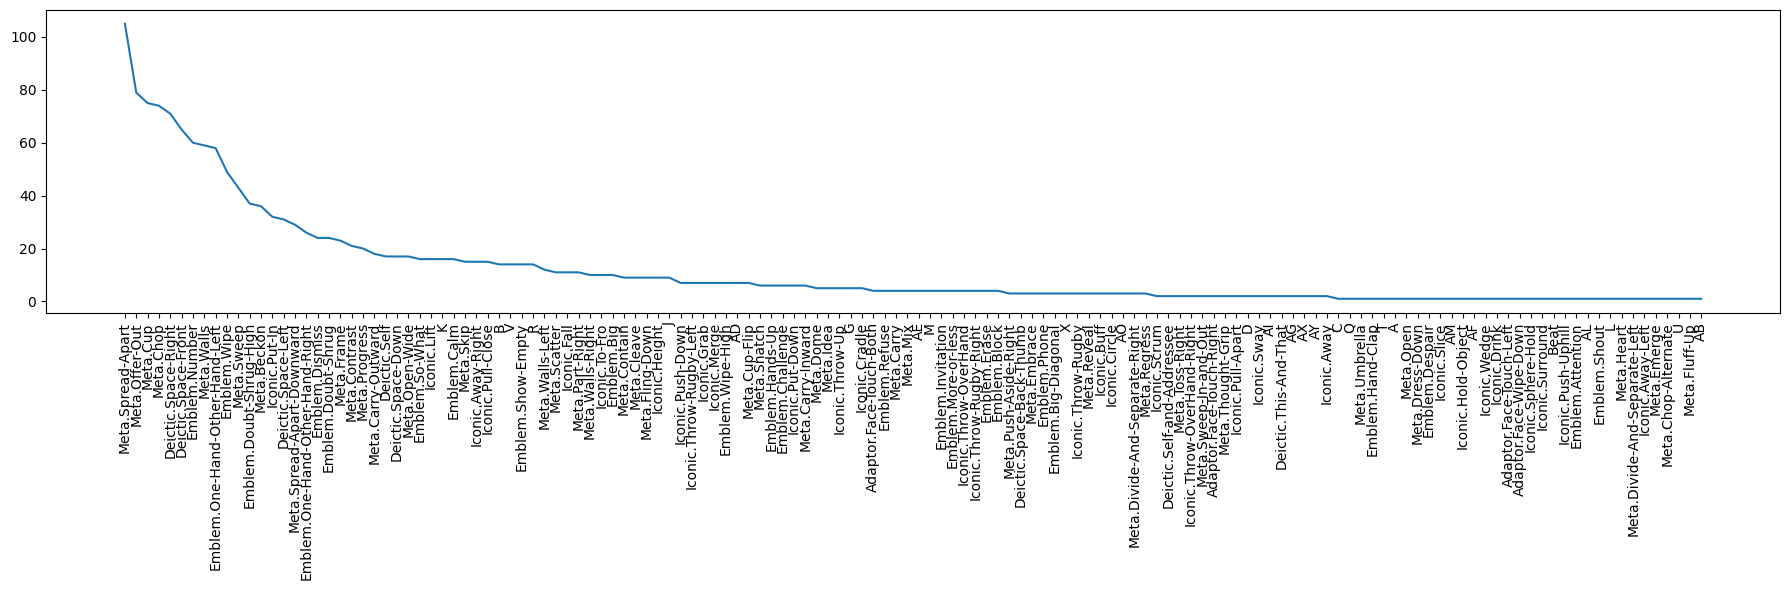

In [9]:
plt.figure(figsize=(18, 6))
plt.plot(category_occurences[1:])
# Source - https://stackoverflow.com/a/37708190
# Posted by scottlittle
# Retrieved 2026-10-29, License - CC BY-SA 3.0

plt.xticks(rotation=90)
plt.tight_layout() 
plt.show()

In [46]:
root_dir = Path("/home/jet/UCDavis/Gesture_Speech_Semantic_Grounding/Semantic Grounding Project/audio/segments")

In [47]:
audio_extensions = {".wav"}

In [49]:
# 1. Does the path actually exist on your system?
print("Does path exist?", root_dir.exists())

# 2. Is Python treating it as a directory?
print("Is it a directory?", root_dir.is_dir())

# 3. What is the exact full path Jupyter is looking at?
print("Resolved absolute path:", root_dir.resolve())
print(root_dir.rglob("*"))
# for audio_path in root_dir.rglob("*"):
#     print("hi: ", audio_path)

Does path exist? True
Is it a directory? True
Resolved absolute path: /home/jet/UCDavis/Gesture_Speech_Semantic_Grounding/Semantic Grounding Project/audio/segments
<generator object Path.rglob at 0x72ecb68d9360>


In [64]:
audio_data = []
audio_suffix_set = set()



for audio_path in root_dir.rglob("*"):

 
    if audio_path.suffix.lower() in audio_extensions:

        # Assuming your structure is root_dir / category_folder / video.mp4
        # The parent folder name acts as the category/label
        category = audio_path.parent.name
        filename = audio_path.name
        relative_path = str(audio_path.relative_to(root_dir))
        absolute_path = str(audio_path.resolve())
        
        try:
            # sf.info() is super fast because it only reads the file header
            duration_sec = round(sf.info(str(audio_path)).duration, 2)
        except Exception as e:
            # Fallback in case a file is corrupted or unsupported
            print(f"Could not read duration for {filename}: {e}")
            duration_sec = 0.0
            
        audio_data.append({
            "filename": filename,
            "category": category,
            "relative_path": relative_path,
            "absolute_path": absolute_path,
            "file_size_mb": round(audio_path.stat().st_size / (1024 * 1024), 2),
            "duration_sec": duration_sec,
            
        })
#     else:
#         audio_suffix_set.add(audio_path)
#         print(f"{audio_path} extension not processed")
    
# print(audio_suffix_set)

In [65]:
audio_df = pd.DataFrame(audio_data)

In [66]:
print(f"Total audio files found: {len(audio_df)}")
display(audio_df.head())

# find . -type f | wc -l # same result

Total audio files found: 3580


,filename,category,relative_path,absolute_path,file_size_mb,duration_sec
0,2-3_seg_308.34-308.66.wav,segments,2-3_seg_308.34-308.66.wav,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.17,1.0
1,2-2_seg_141.68-142.04.wav,segments,2-2_seg_141.68-142.04.wav,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.34,2.0
2,4-2_seg_562.67-563.07.wav,segments,4-2_seg_562.67-563.07.wav,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.34,2.0
3,1-1_seg_382.57-382.97.wav,segments,1-1_seg_382.57-382.97.wav,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.17,1.0
4,4-4_seg_82.77-83.22.wav,segments,4-4_seg_82.77-83.22.wav,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.34,2.0


In [74]:
audio_df.to_csv("audio_dataset_index.csv", index=False)

In [77]:
audio_category_occurences = audio_df['duration_sec'].value_counts()
print(audio_category_occurences)

duration_sec
1.0    1947
2.0    1633
Name: count, dtype: int64


/tmp/ipykernel_151764/1603736629.py:2: FutureWarning: The behavior of obj[i:j] with a float-dtype index is deprecated. In a future version, this will be treated as positional instead of label-based. For label-based slicing, use obj.loc[i:j] instead
  plt.plot(audio_category_occurences[1:])


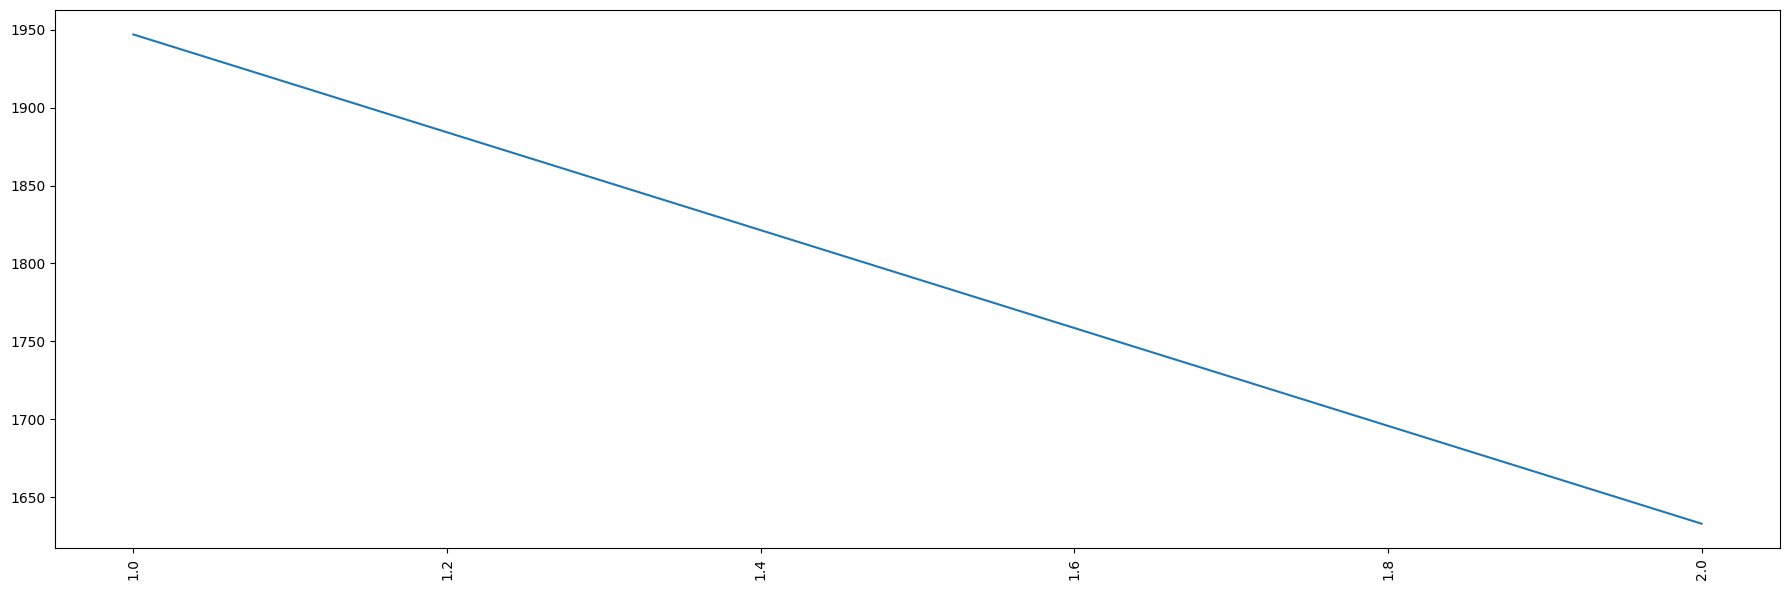

In [72]:
plt.figure(figsize=(18, 6))
plt.plot(audio_category_occurences[1:])
# Source - https://stackoverflow.com/a/37708190
# Posted by scottlittle
# Retrieved 2026-10-29, License - CC BY-SA 3.0

plt.xticks(rotation=90)
plt.tight_layout() 
plt.show()